# Disease Prediction from Medical Data

CodeAlpha Machine Learning internship, Task 4.

Predict whether a breast tumor is malignant or benign using the Breast Cancer Wisconsin (Diagnostic) dataset from scikit-learn. Class 0 = malignant, class 1 = benign.

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame

print("Shape:", df.shape)
df.head()

Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 2. Explore the data

In [2]:
print(df['target'].value_counts())
print("Missing values:", df.isnull().sum().sum())
print(data.target_names)   # ['malignant' 'benign']
df.describe().T.head(10)

target
1    357
0    212
Name: count, dtype: int64
Missing values: 0
['malignant' 'benign']


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


## 3. Train/test split and scaling

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Train: (455, 30) | Test: (114, 30)
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


## 4. Baseline model: Logistic Regression

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



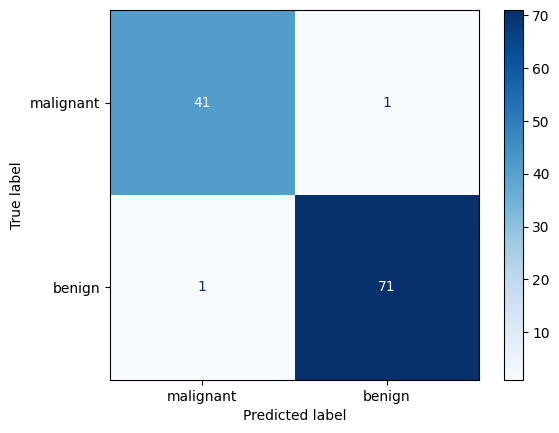

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)

print(classification_report(y_test, y_pred, target_names=data.target_names))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(cmap='Blues')
plt.show()

## 5. Compare four models on the test set

In [6]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score

models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42), True),
    "SVM": (SVC(kernel='rbf', random_state=42), True),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42), False),
    "XGBoost": (XGBClassifier(eval_metric='logloss', random_state=42), False),
}

results = []
for name, (model, needs_scaling) in models.items():
    Xtr = X_train_scaled if needs_scaling else X_train
    Xte = X_test_scaled if needs_scaling else X_test
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Recall (malignant)": recall_score(y_test, pred, pos_label=0),
        "Precision (malignant)": precision_score(y_test, pred, pos_label=0),
    })

pd.DataFrame(results).round(3)

,Model,Accuracy,Recall (malignant),Precision (malignant)
0,Logistic Regression,0.982,0.976,0.976
1,SVM,0.982,0.976,0.976
2,Random Forest,0.956,0.929,0.951
3,XGBoost,0.956,0.905,0.974


## 6. 5-fold cross-validation

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42),
}

scoring = {
    "acc": "accuracy",
    "recall_mal": make_scorer(recall_score, pos_label=0),
}

rows = []
for name, model in cv_models.items():
    scores = cross_validate(model, X, y, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "Accuracy": scores["test_acc"].mean(),
        "Recall (malignant)": scores["test_recall_mal"].mean(),
        "Recall std": scores["test_recall_mal"].std(),
    })

pd.DataFrame(rows).round(3)

,Model,Accuracy,Recall (malignant),Recall std
0,Logistic Regression,0.974,0.944,0.052
1,SVM,0.977,0.958,0.037
2,Random Forest,0.954,0.934,0.050
3,XGBoost,0.963,0.944,0.041


## 7. Final model (SVM): ROC-AUC and saved pipeline

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

ROC-AUC: 0.995


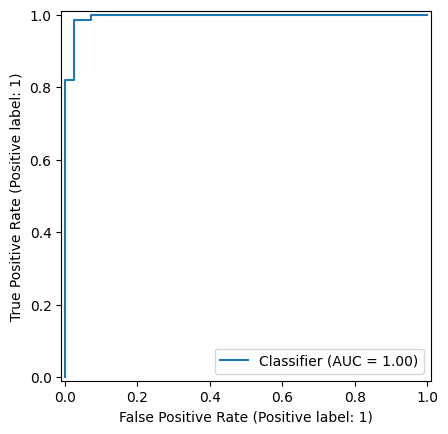

['disease_model.joblib']

In [9]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay, classification_report
import joblib

final_model = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42))
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_score = final_model.decision_function(X_test)

print(classification_report(y_test, y_pred, target_names=data.target_names))
print("ROC-AUC:", round(roc_auc_score(y_test, y_score), 3))

RocCurveDisplay.from_predictions(y_test, y_score)
plt.show()

joblib.dump(final_model, "disease_model.joblib")